<img src="../imagenes/avista2.png" width="250" height="100" />
 
## Prueba – Análisis de datos: volumen transaccional por operación y terminal


**Candidato:** Daniel Felipe Pérez Grajales . dfperezg@unal.edu.co<br>

----

## Prueba – Análisis de datos 
<div style="text-align: justify">
Una entidad bancaria desea anticipar el volumen de transacciones por operación que ocurrirán en una ventana de tiempo de 15 días. Para llevar esta tarea a cabo se cuenta con la información de las operaciones realizadas en las diferentes terminales por un periodo de 4 meses. 

El objetivo es utilizar estos datos para proporcionar a la entidad un entendimiento del comportamiento del volumen de transacciones por operación y por terminal, y generar recomendaciones que permitan soportar decisiones que optimicen la utilización de los terminales. 

Es requisito incluir cualquier código que desarrolle para el análisis solicitado. También recomendamos tomar las suposiciones que considere necesarias y explicar cualquier dificultad que pueda encontrar. 

1. Realice los procedimientos que considere necesarios (análisis exploratorio, visualizaciones, …) que le permitan generar un mayor entendimiento de la información y del comportamiento del volumen transaccional. Describa el procedimiento y de las explicaciones correspondientes de las gráficas generadas. Sugerimos reportar información relevante que de una interpretación clara sobre el conjunto de datos.

2. Construya un modelo predictivo que pueda ser utilizado para estimar la demanda diaria por operación en cada terminal para una ventana de tiempo de 15 días siguientes a la última fecha reportada en la base de información. Es importante que incluya sus comentarios y opiniones sobre:

* a. La calidad y cantidad de la información para construir el modelo solicitado. 
* b. Justificación del modelo utilizado y que alternativas consideró y como las evaluó. 
* c. ¿Qué tan válido es el modelo propuesto? Incluya indicadores de desempeño utilizados. 


Por comodidad y tiempo, el modelo no debe abarcar la totalidad de operaciones y terminales. Se debe construir para 5 terminales y 5 operaciones de su libre elección. Incluir los criterios de selección utilizados. 

3. Elabore un informe ejecutivo en donde reporte los hallazgos obtenidos de los dos puntos anteriores a través de los indicadores que considere necesarios. Explique brevemente como la entidad podría tomar provecho de los resultados del modelo. 

Descripción campos 
Columna 
Descripción 
fecha 
idTerminal 
Fecha y hora de la transacción  
Identificador de la terminal 
oper 
Tipo de operación realizada

--------

**Objetivo.** Entender el comportamiento del volumen de transacciones por operación y terminal, y construir un modelo que estime la **demanda diaria por operación en cada terminal para los 15 días siguientes a la última fecha reportada** (1–15 de junio de 2017), para apoyar decisiones de utilización de terminales.

**Solución prueba**
1. Carga y calidad de datos
2. Análisis exploratorio (punto 1 de la prueba)
3. Selección de 5 terminales y 5 operaciones
4. Modelo predictivo: features, alternativas, backtesting y validez (punto 2)
5. Pronóstico 1–15 jun 2017
6. Conclusiones y uso para la entidad (insumo del punto 3; el informe ejecutivo está en el `.pptx`)

**Supuestos generales** (se justifican donde se usan)
- El campo `oper` es un código de tipo de operación sin diccionario; se analiza por código.
- Cada fila es una transacción; el volumen es el **conteo** de filas.
- Los patrones de calendario (festivos, quincena) corresponden a **Colombia** (consistente con las caídas observadas el 20-mar, 13/14-abr, 1-may y 29-may de 2017, y con picos en los días 15 y último de cada mes).
</div>

In [1]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import statsmodels.api as sm, lightgbm as lgb
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)

OUT = 'imagenes'; FIG = f'{OUT}/figs'
os.makedirs(FIG, exist_ok=True)
DATA = Path('data/data_01/data_01.txt')
if not DATA.is_file():
    DATA = Path('..') / DATA
if not DATA.is_file():
    raise FileNotFoundError(f'Dataset not found: {DATA.resolve()}')

ACC, GRY, DK = '#1F6F8B', '#9AA5AD', '#22313F'
PAL = ['#1F6F8B', '#E07A1F', '#5B8E3E', '#8E5BA8', '#B23A48']
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
                     'font.size': 10, 'axes.edgecolor': '#666'})
def save(name): plt.savefig(f'{FIG}/{name}.png', bbox_inches='tight', facecolor='white')

## 1. Carga y calidad de los datos

In [2]:
df = pd.read_csv(DATA, sep='\t', parse_dates=['fecha'])
df['d'] = df['fecha'].dt.normalize()
df['hora'] = df['fecha'].dt.hour
print('Filas:', f'{len(df):,}', '| Rango:', df.fecha.min(), '→', df.fecha.max())
print('Terminales:', df.idTerminal.nunique(), '| Operaciones:', df.oper.nunique())
print('Nulos:\n', df.isna().sum().to_string())
print('Filas duplicadas exactas:', df.duplicated(['fecha', 'idTerminal', 'oper']).sum())
print('Archivo ordenado cronológicamente:', df.fecha.is_monotonic_increasing, '(viene ordenado por terminal, no por fecha)')

Filas: 775,466 | Rango: 2017-01-31 08:19:33 → 2017-05-31 23:59:48
Terminales: 47 | Operaciones: 46
Nulos:
 fecha         0
idTerminal    0
oper          0
d             0
hora          0
Filas duplicadas exactas: 0
Archivo ordenado cronológicamente: False (viene ordenado por terminal, no por fecha)


In [3]:
# Ciclo de vida de cada terminal
life = df.groupby('idTerminal').agg(tx=('oper', 'size'), primer_dia=('d', 'min'), ultimo_dia=('d', 'max'), dias_activos=('d', 'nunique'))
FULL_START, FULL_END = pd.Timestamp('2017-02-01'), pd.Timestamp('2017-05-30')
life['cobertura_completa'] = (life.primer_dia <= FULL_START) & (life.ultimo_dia >= FULL_END)
print('Terminales que NO cubren todo el periodo:')
print(life[~life.cobertura_completa].to_string())

Terminales que NO cubren todo el periodo:
               tx primer_dia ultimo_dia  dias_activos  cobertura_completa
idTerminal                                                               
1515         4325 2017-04-06 2017-05-31            46               False
1828        19576 2017-01-31 2017-05-19           109               False
1963        16429 2017-01-31 2017-04-07            67               False


**Hallazgos de calidad**
- Sin nulos ni duplicados; 775.466 transacciones, 47 terminales y 46 códigos de operación entre el 31-ene y el 31-may-2017 (121 días).
- **Terminales con vida parcial:** 1963 deja de reportar el 7-abr, 1828 el 19-may, y 1515 aparece recién el 6-abr. Con ellas el nivel "normal" no es comparable → se excluyen de la selección de modelado (serían baja/alta de terminal, no demanda).
- **Ceros:** se generan los días sin transacciones como cero (no faltantes) porque un terminal sin transacciones un día es información (domingo, festivo, falla). Sin este paso los promedios se sobreestiman.
- El archivo no está ordenado por fecha; se ordena antes de agregar.
- Con solo 4 meses (≈17 semanas, 4–5 ciclos de quincena, 5 festivos) no hay estacionalidad anual observable. Es la principal limitación del modelo.

## 2. Análisis exploratorio
### 2.1 Calendario de referencia (festivos y quincenas)
Se define "día de pago" como el 15 y el último día del mes, moviéndose al día hábil anterior si cae en fin de semana o festivo (práctica habitual en Colombia). Se derivan los *días hábiles desde el último pago* (`bd_since`) y *hasta el próximo pago* (`bd_to`).

In [4]:
HOL = pd.to_datetime(['2017-01-09', '2017-03-20', '2017-04-13', '2017-04-14', '2017-05-01', '2017-05-29', '2017-06-19', '2017-06-26'])
cal_days = pd.date_range('2017-01-01', '2017-07-31')
is_bd = pd.Series(~((cal_days.dayofweek >= 5) | cal_days.isin(HOL)), index=cal_days)
bd_cum = is_bd.cumsum()

def payday(y, m, which):
    dt = pd.Timestamp(y, m, 15) if which == 15 else pd.Timestamp(y, m, 1) + pd.offsets.MonthEnd(0)
    while not is_bd[dt]: dt -= pd.Timedelta(days=1)
    return dt
PAY = pd.DatetimeIndex(sorted(payday(2017, m, w) for m in range(1, 8) for w in (15, 30)))

def calendar_features(dates):
    f = pd.DataFrame({'d': pd.DatetimeIndex(dates)})
    f['dow'] = f.d.dt.dayofweek; f['dom'] = f.d.dt.day
    f['hol'] = f.d.isin(HOL).astype(int)
    f['is_pay'] = f.d.isin(PAY).astype(int)
    last = [PAY[PAY <= t].max() for t in f.d]; nxt = [PAY[PAY > t].min() for t in f.d]
    f['bd_since'] = [bd_cum[t] - bd_cum[l] for t, l in zip(f.d, last)]
    f['bd_to'] = [bd_cum[n] - bd_cum[t] for t, n in zip(f.d, nxt)]
    f['post_hol'] = ((~is_bd[f.d - pd.Timedelta(days=1)].values) & is_bd[f.d].values).astype(int)
    return f
ALL_DAYS = pd.date_range('2017-01-31', '2017-05-31')
CAL = calendar_features(pd.date_range('2017-01-31', '2017-06-15'))
print('Días de pago en el periodo:', [d.strftime('%d-%b') for d in PAY if d <= pd.Timestamp('2017-06-15')])

Días de pago en el periodo: ['13-Jan', '31-Jan', '15-Feb', '28-Feb', '15-Mar', '31-Mar', '12-Apr', '28-Apr', '15-May', '31-May', '15-Jun']


### 2.2 Serie diaria total

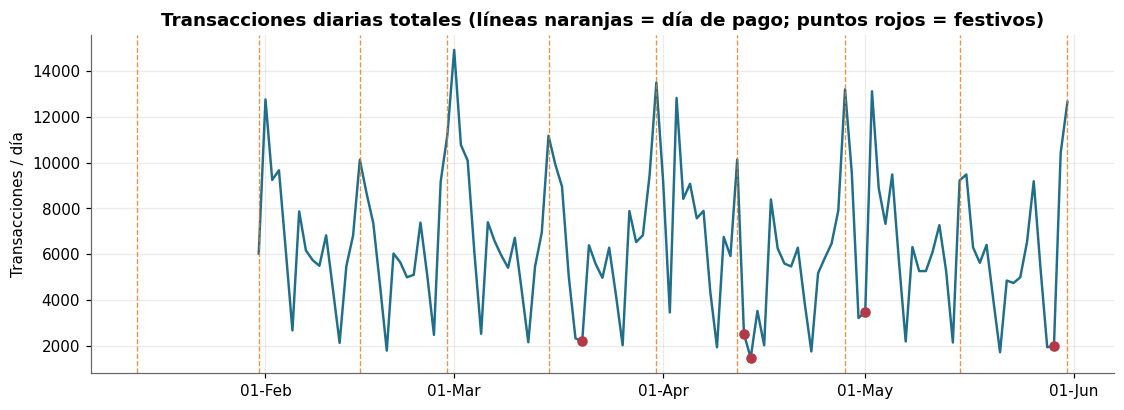

count      121.0
mean      6409.0
std       2971.0
min       1472.0
25%       4743.0
50%       6112.0
75%       8394.0
max      14923.0


In [5]:
daily = df.groupby('d').size().reindex(ALL_DAYS, fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, color=ACC, lw=1.6)
for p in PAY[PAY <= '2017-05-31']: ax.axvline(p, color='#E07A1F', ls='--', lw=.9, alpha=.8)
for h in HOL[HOL <= '2017-05-31'][1:]: ax.scatter(h, daily[h], color='#B23A48', zorder=5, s=35)
ax.set_title('Transacciones diarias totales (líneas naranjas = día de pago; puntos rojos = festivos)')
ax.set_ylabel('Transacciones / día'); ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
save('fig_daily'); plt.show()
print(daily.describe().round(0).to_string())

**Lectura.** La serie es fuertemente cíclica: picos a fin de mes/inicio del siguiente y a mitad de mes (≈10–15 mil tx/día vs. ≈5–7 mil en un día hábil "normal"), valles los domingos (≈2 mil) y caídas marcadas en festivos (20-mar, 13/14-abr, 1-may, 29-may). Los picos más altos ocurren **el día de pago y el día hábil siguiente** (p. ej. 1-feb, 1-mar, 3-abr, 2-may).

### 2.3 Día de la semana, quincena y mapa de calor

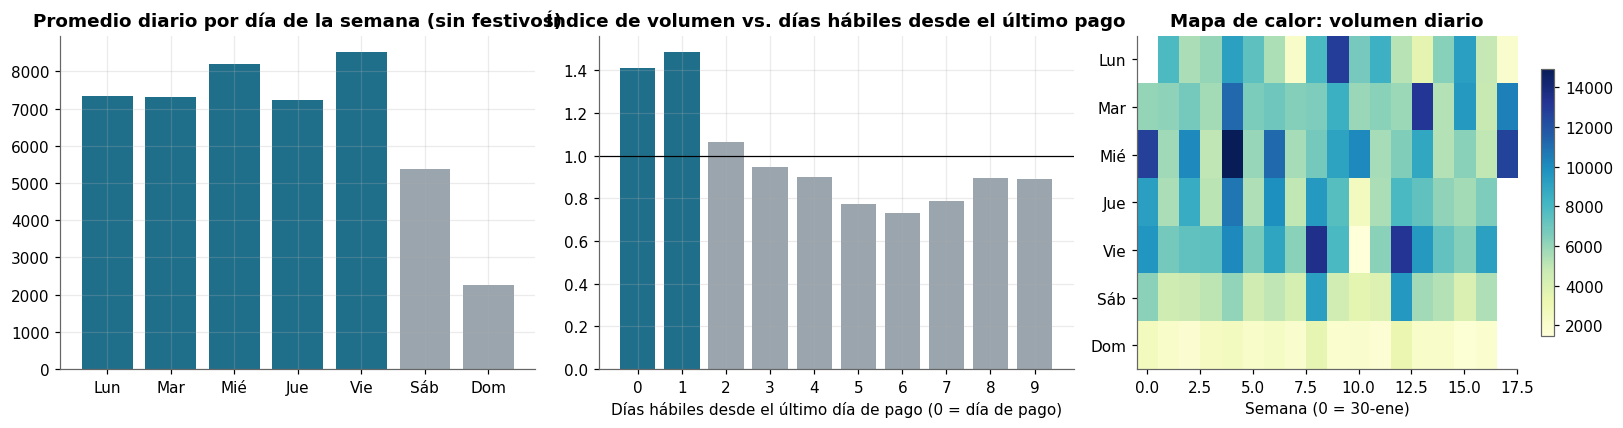

dow
Lun    7345.0
Mar    7322.0
Mié    8190.0
Jue    7224.0
Vie    8531.0
Sáb    5364.0
Dom    2264.0
          mean  count
bd_since             
0         1.41      8
1         1.49      8
2         1.06      8
3         0.95      8
4         0.90      8
5         0.78      8
6         0.73      8
7         0.79      8
8         0.89      7
9         0.89      6


In [6]:
dd = daily.rename('y').reset_index().rename(columns={'index': 'd'}).merge(CAL, on='d')
dd['bd'] = dd.d.map(is_bd)
dow_names = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
dow_mean = dd[~dd.hol.astype(bool)].groupby('dow').y.mean()
# índice de quincena: volumen de un día hábil / promedio de días hábiles del mismo día de la semana
bdd = dd[dd.bd & (dd.d > '2017-01-31')].copy()
bdd['idx'] = bdd.y / bdd.groupby('dow').y.transform('mean')
pay_idx = bdd.groupby('bd_since').idx.agg(['mean', 'count']).loc[0:9]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].bar(dow_names, dow_mean.values, color=[ACC] * 5 + [GRY, GRY]); axs[0].set_title('Promedio diario por día de la semana (sin festivos)')
axs[1].bar(pay_idx.index.astype(str), pay_idx['mean'], color=[ACC if v > 1.1 else GRY for v in pay_idx['mean']])
axs[1].axhline(1, color='k', lw=.8); axs[1].set_title('Índice de volumen vs. días hábiles desde el último pago')
axs[1].set_xlabel('Días hábiles desde el último día de pago (0 = día de pago)')
wk = ((dd.d - pd.Timestamp('2017-01-30')).dt.days // 7)
hm = dd.assign(wk=wk).pivot(index='dow', columns='wk', values='y')
im = axs[2].imshow(hm.values, aspect='auto', cmap='YlGnBu'); axs[2].set_yticks(range(7)); axs[2].set_yticklabels(dow_names)
axs[2].set_xlabel('Semana (0 = 30-ene)'); axs[2].set_title('Mapa de calor: volumen diario'); axs[2].grid(False)
plt.colorbar(im, ax=axs[2], shrink=.8)
plt.tight_layout(); save('fig_dow_pay'); plt.show()
print(dow_mean.round(0).rename(dict(enumerate(dow_names))).to_string()); print(pay_idx.round(2).to_string())

**Lectura.**
- **Día de la semana:** viernes y miércoles son los más cargados (≈8,5 y 8,2 mil), sábado ≈5,4 mil y domingo ≈2,3 mil (≈28 % de un miércoles).
- **Quincena:** el volumen en día hábil es ≈**41 % superior al normal el día de pago y ≈49 % el día hábil siguiente**; luego decae hasta quedar por debajo del promedio desde el día hábil 3 (mínimo ≈0,73 el día 6). Es el **driver de demanda más importante después del día de la semana** y justifica incluir variables de quincena en el modelo.
- El mapa de calor confirma la regularidad semanal, las semanas "calientes" de quincena y las celdas claras de festivos.

### 2.4 Perfil horario

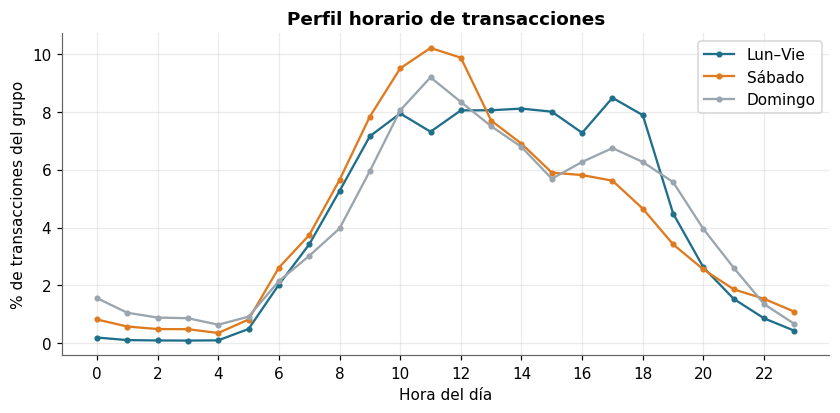

Entre 9:00 y 18:59 se concentra 77% de las transacciones; 00:00–04:59 solo 1.1%.


In [7]:
hh = df.assign(grp=np.where(df.d.dt.dayofweek < 5, 'Lun–Vie', np.where(df.d.dt.dayofweek == 5, 'Sábado', 'Domingo'))).groupby(['hora', 'grp']).size().unstack()
hh = hh / hh.sum()
fig, ax = plt.subplots(figsize=(9, 3.8))
for c, col in zip(['Lun–Vie', 'Sábado', 'Domingo'], [ACC, '#E07A1F', GRY]): ax.plot(hh.index, hh[c] * 100, marker='o', ms=3, label=c, color=col)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Hora del día'); ax.set_ylabel('% de transacciones del grupo'); ax.set_title('Perfil horario de transacciones'); ax.legend()
save('fig_hour'); plt.show()
h_all = df.groupby('hora').size() / len(df)
print(f'Entre 9:00 y 18:59 se concentra {h_all.loc[9:18].sum():.0%} de las transacciones; 00:00–04:59 solo {h_all.loc[0:4].sum():.1%}.')

**Lectura.** Jornada concentrada entre 9 h y 18 h (77 % de las transacciones) con una leve baja al mediodía; la actividad nocturna (0–5 h) es marginal (1 %). **La ventana crítica de capacidad es 9–18 h** y el nivel diario es lo que debe pronosticarse.

### 2.5 Operaciones: concentración y sensibilidad a la quincena

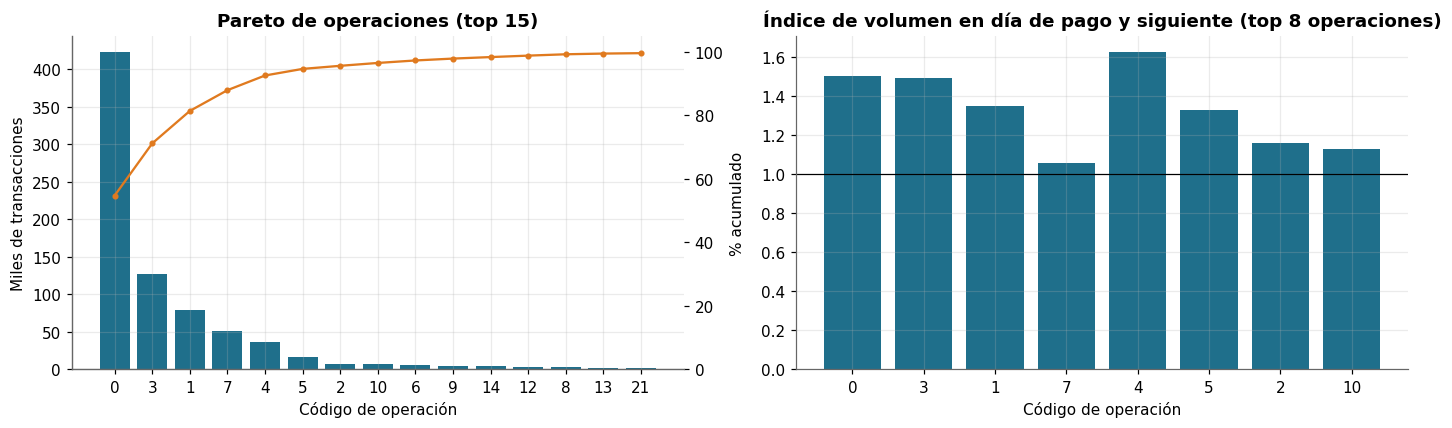

Participación: {0: 0.547, 3: 0.164, 1: 0.102, 7: 0.065, 4: 0.046, 5: 0.021}
Acumulado top 5: 0.925 | top 10: 0.978
Índice de quincena: {0: 1.5, 3: 1.49, 1: 1.35, 7: 1.05, 4: 1.63, 5: 1.33, 2: 1.16, 10: 1.13}


In [8]:
ops = df.oper.value_counts()
cum = ops.cumsum() / ops.sum()
top8 = ops.index[:8]
# uplift de quincena por operación: índice (vs mismo día de la semana) en días hábiles con bd_since in {0,1}
od = df[df.oper.isin(top8)].groupby(['oper', 'd']).size().unstack(0).reindex(ALL_DAYS, fill_value=0)
od = od.join(CAL.set_index('d')[['dow', 'bd_since']]).join(is_bd.rename('bd'))
od = od[od.bd & (od.index > '2017-01-31')]
upl = {}
for o in top8:
    idx = od[o] / od.groupby('dow')[o].transform('mean')
    upl[o] = idx[od.bd_since.isin([0, 1])].mean()
upl = pd.Series(upl)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].bar(range(len(ops.head(15))), ops.head(15).values / 1e3, color=ACC); axs[0].set_xticks(range(15)); axs[0].set_xticklabels(ops.head(15).index)
ax2 = axs[0].twinx(); ax2.plot(range(15), cum.head(15).values * 100, color='#E07A1F', marker='o', ms=3); ax2.set_ylim(0, 105); ax2.set_ylabel('% acumulado'); ax2.grid(False)
axs[0].set_title('Pareto de operaciones (top 15)'); axs[0].set_ylabel('Miles de transacciones'); axs[0].set_xlabel('Código de operación')
axs[1].bar(upl.index.astype(str), upl.values, color=ACC); axs[1].axhline(1, color='k', lw=.8)
axs[1].set_title('Índice de volumen en día de pago y siguiente (top 8 operaciones)'); axs[1].set_xlabel('Código de operación')
plt.tight_layout(); save('fig_ops'); plt.show()
print('Participación:', (ops.head(6) / ops.sum()).round(3).to_dict())
print('Acumulado top 5:', round(cum.iloc[4], 3), '| top 10:', round(cum.iloc[9], 3))
print('Índice de quincena:', upl.round(2).to_dict())

**Lectura.**
- Alta concentración: la operación **0 aporta 55 %** del volumen; las 5 primeras (0, 3, 1, 7, 4) reúnen **92,5 %** y las 10 primeras 98 %. Las otras 41 operaciones suman <8 % (cola larga con pocas transacciones por día) → **no pronosticables diariamente con fiabilidad**.
- La sensibilidad a la quincena difiere por operación: las **operaciones 4 (×1,63), 0 (×1,50) y 3 (×1,49)** se disparan en día de pago; la **7 casi no reacciona (×1,05)**. Conviene dimensionar capacidad por operación y no solo por total.

### 2.6 Terminales: volumen, concentración y utilización

Top 10 terminales = 33% del volumen; top 20 = 58%; el 20 % inferior (≈9 terminales) = 9.4%
Relación entre la terminal más y menos cargada (cobertura completa): 7.1x


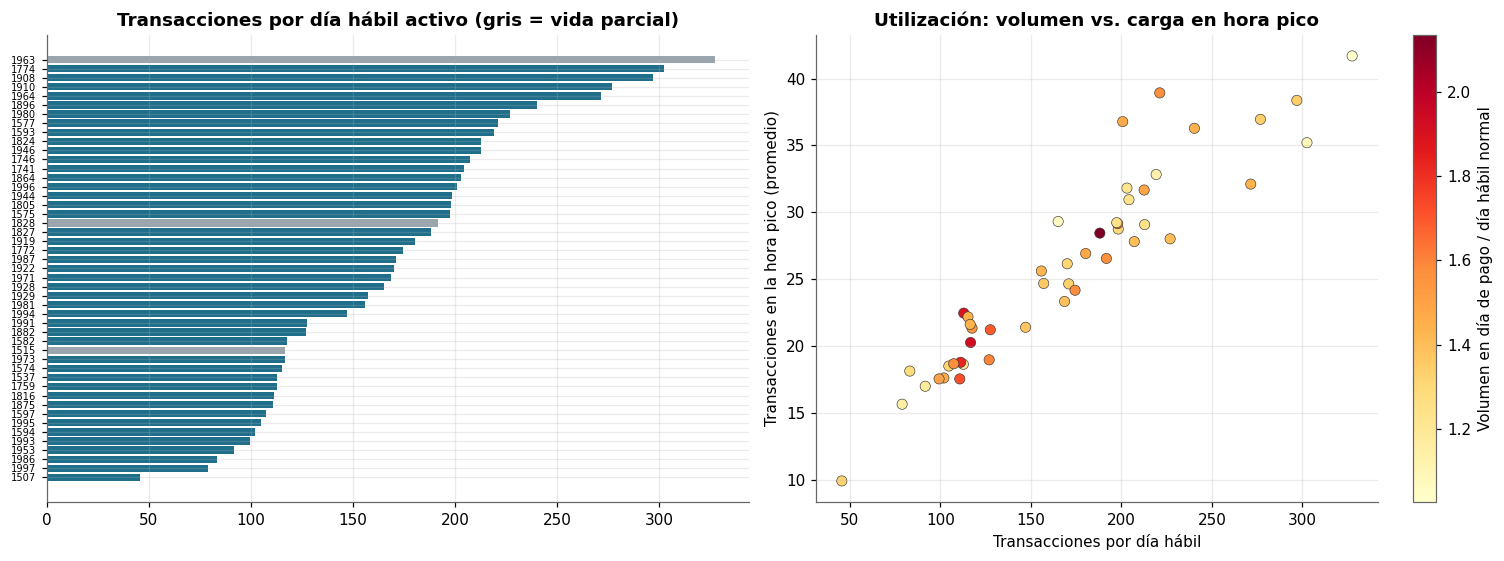

               tx  tx_dia_habil  pico_hora  ratio_pago  cobertura_completa
idTerminal                                                                
1774        32122         302.5       35.2         1.1                True
1908        30933         297.0       38.4         1.3                True
1964        29999         271.5       32.1         1.4                True
1910        26789         276.8       37.0         1.3                True
1980        25243         227.0       28.0         1.4                True
              tx  tx_dia_habil  pico_hora  ratio_pago  cobertura_completa
idTerminal                                                               
1597        9188         107.4       18.7         1.6                True
1993        8794          99.4       17.6         1.5                True
1997        8498          78.9       15.7         1.2                True
1986        8183          83.2       18.1         1.3                True
1507        4496          45.6 

In [9]:
bdays_n = int(is_bd[ALL_DAYS].sum())
tb = df[df.d.map(is_bd)]
per_term = pd.DataFrame({'tx': df.groupby('idTerminal').size()})
# transacciones por día hábil con actividad
act_bd = tb.groupby('idTerminal').d.nunique()
per_term['tx_dia_habil'] = tb.groupby('idTerminal').size() / act_bd
hourly = tb.groupby(['idTerminal', 'd', 'hora']).size().rename('n').reset_index()
per_term['pico_hora'] = hourly.groupby(['idTerminal', 'd']).n.max().groupby('idTerminal').mean()
pay_days = tb[tb.d.isin(PAY)].groupby('idTerminal').size() / tb[tb.d.isin(PAY)].groupby('idTerminal').d.nunique()
per_term['ratio_pago'] = pay_days / per_term.tx_dia_habil
per_term = per_term.join(life[['cobertura_completa']])
per_term = per_term.sort_values('tx', ascending=False)
share = per_term.tx / per_term.tx.sum()
print(f'Top 10 terminales = {share.head(10).sum():.0%} del volumen; top 20 = {share.head(20).sum():.0%}; el 20 % inferior (≈9 terminales) = {share.tail(9).sum():.1%}')
print(f'Relación entre la terminal más y menos cargada (cobertura completa): {per_term[per_term.cobertura_completa].tx.max() / per_term[per_term.cobertura_completa].tx.min():.1f}x')

fig, axs = plt.subplots(1, 2, figsize=(14, 5.2))
pt = per_term.sort_values('tx_dia_habil')
axs[0].barh(pt.index.astype(str), pt.tx_dia_habil, color=[ACC if c else GRY for c in pt.cobertura_completa])
axs[0].set_title('Transacciones por día hábil activo (gris = vida parcial)'); axs[0].tick_params(axis='y', labelsize=6.5)
sc = axs[1].scatter(per_term.tx_dia_habil, per_term.pico_hora, c=per_term.ratio_pago, cmap='YlOrRd', s=45, edgecolor='#333', lw=.4)
plt.colorbar(sc, ax=axs[1], label='Volumen en día de pago / día hábil normal')
axs[1].set_xlabel('Transacciones por día hábil'); axs[1].set_ylabel('Transacciones en la hora pico (promedio)')
axs[1].set_title('Utilización: volumen vs. carga en hora pico')
plt.tight_layout(); save('fig_terminals'); plt.show()
print(per_term.head(5).round(1).to_string()); print(per_term[per_term.cobertura_completa].tail(5).round(1).to_string())

**Lectura.**
- **Alta heterogeneidad:** la terminal más cargada procesa ≈7x las transacciones de la menos cargada con cobertura completa. Las 10 primeras terminales concentran ≈ 1/3 del volumen.
- La carga en **hora pico** crece con el volumen diario (≈35–38 tx en la hora pico de las terminales líderes vs. ≈10–19 en las de menor volumen). En día de pago casi todas suben entre 1,1x y 1,6x su volumen hábil normal.
- Terminales de bajo volumen (1507, 1986, 1997, 1993, 1597) son candidatas a revisión de ubicación/configuración.

### 2.7 Mezcla de operaciones por terminal

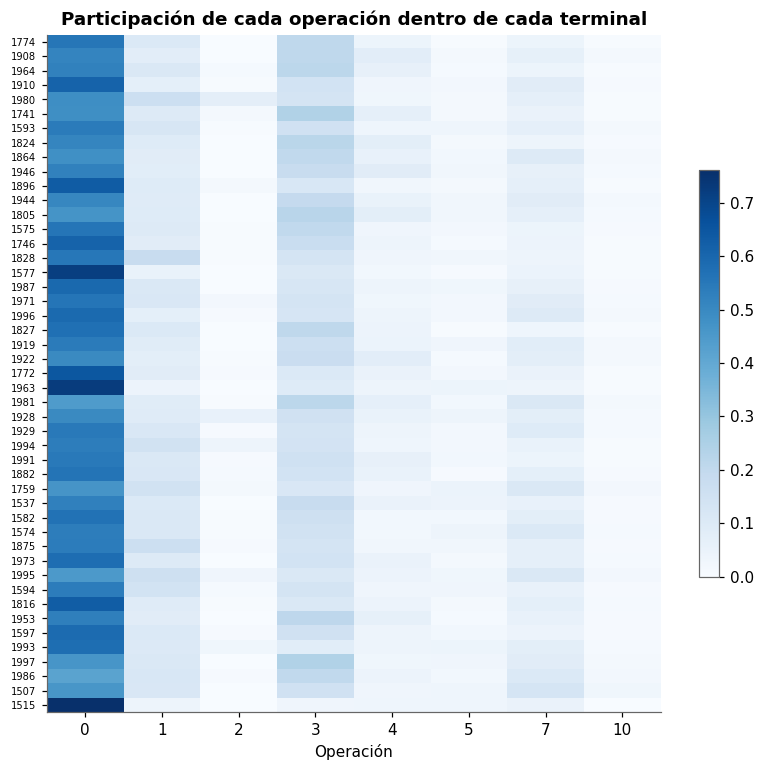

Participación de op 0 por terminal: min 42%, mediana 54%, máx 76%
Casos atípicos de op 2: {1980: 0.072, 1928: 0.059, 1994: 0.037}


In [10]:
mix = df[df.oper.isin(ops.index[:8])].pivot_table(index='idTerminal', columns='oper', values='d', aggfunc='size', fill_value=0)
mix = mix.div(df.groupby('idTerminal').size(), axis=0).loc[per_term.index]
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(mix.values, aspect='auto', cmap='Blues'); ax.grid(False)
ax.set_xticks(range(mix.shape[1])); ax.set_xticklabels(mix.columns); ax.set_yticks(range(len(mix))); ax.set_yticklabels(mix.index, fontsize=6.5)
ax.set_title('Participación de cada operación dentro de cada terminal'); ax.set_xlabel('Operación'); plt.colorbar(im, shrink=.6)
save('fig_mix'); plt.show()
print('Participación de op 0 por terminal: min %.0f%%, mediana %.0f%%, máx %.0f%%' % (mix[0].min() * 100, mix[0].median() * 100, mix[0].max() * 100))
print('Casos atípicos de op 2:', mix[2].sort_values(ascending=False).head(3).round(3).to_dict())

**Lectura.** Todas las terminales comparten la misma "forma" (op 0 domina, seguida de 3 y 1), pero la participación de la op 0 va de 42 % a 76 % según la terminal, y terminales como 1980 y 1928 usan la op 2 mucho más que el resto (7 % y 6 % vs. <1 % típico). Por eso la demanda **por operación y por terminal** no se obtiene repartiendo el total: hace falta modelarla por serie.

## 3. Selección de 5 terminales y 5 operaciones
**Criterios**
- **Operaciones:** (i) mayor volumen acumulado, (ii) actividad todos los días del periodo (series sin huecos) y (iii) volumen medio suficiente por terminal-día para que un modelo estadístico tenga señal por encima del ruido de conteo. → códigos **0, 3, 1, 7, 4** (92 % del volumen).
- **Terminales:** (i) cobertura completa (activas todo el periodo; se excluyen 1963, 1828, 1515), (ii) mayor volumen — donde una mejora de pronóstico tiene mayor impacto en utilización — y (iii) mezclas de operaciones distintas entre sí. → **1774, 1908, 1964, 1910, 1980**.

*Sesgo asumido:* se eligen las terminales y operaciones de mayor volumen, donde el modelo es más fiable; más abajo se evalúa si los resultados se sostienen en las 44 terminales con cobertura completa.

In [11]:
OPS = list(ops.index[:5]); print('Operaciones:', OPS)
full = life[life.cobertura_completa].sort_values('tx', ascending=False)
TERM = list(full.index[:5]); print('Terminales:', TERM)
opd = df[df.oper.isin(OPS)].groupby('oper').agg(tx=('d', 'size'), dias=('d', 'nunique'))
print(opd.assign(share=(opd.tx / len(df)).round(3)).to_string())
sel_tab = df[df.idTerminal.isin(TERM) & df.oper.isin(OPS)].pivot_table(index='idTerminal', columns='oper', values='d', aggfunc='size', fill_value=0)
print((sel_tab / 121).round(1).to_string(), '\n^ promedio de transacciones por día en cada serie (121 días)')

Operaciones: [0, 3, 1, 7, 4]
Terminales: [1774, 1908, 1964, 1910, 1980]
          tx  dias  share
oper                     
0     423929   121  0.547
1      79195   121  0.102
3     127399   121  0.164
4      35817   121  0.046
7      50662   121  0.065
oper            0     1     3     4     7
idTerminal                               
1774        147.0  28.1  54.9  10.3  10.6
1908        131.1  20.2  52.5  19.9  16.4
1910        135.5  15.6  31.2   7.2  18.8
1964        129.1  27.4  53.0  15.4   9.7
1980        101.4  34.4  27.9   5.7  13.7 
^ promedio de transacciones por día en cada serie (121 días)


### 3.1 Descomposición y estacionariedad de la demanda diaria agregada

Para estudiar la dinámica temporal en la misma escala de la comparación global del pronóstico, se agregan por día las 25 combinaciones seleccionadas (5 terminales × 5 operaciones). En estas series individuales solo el 1.3 % de los días tiene cero transacciones. La descomposición STL separa tendencia, ciclo semanal y residuo, y es robusta frente a picos como los días de pago. La periodicidad 7 se justifica por el calendario semanal; con solo cuatro meses de observaciones no se estima una estacionalidad anual. La estimación Box–Cox ayuda a evaluar estabilización de varianza; si se aplica al modelo, su parámetro se estima solo con cada conjunto de entrenamiento. La estructura de exploración sigue el enfoque del [artículo de referencia](https://cienciadedatos.net/documentos/py29-forecasting-demanda-energia-electrica-python), adaptado a los datos transaccionales.

25 series agregadas: 121 días | 2017-01-31 a 2017-05-31 | días con cero transacciones: 0


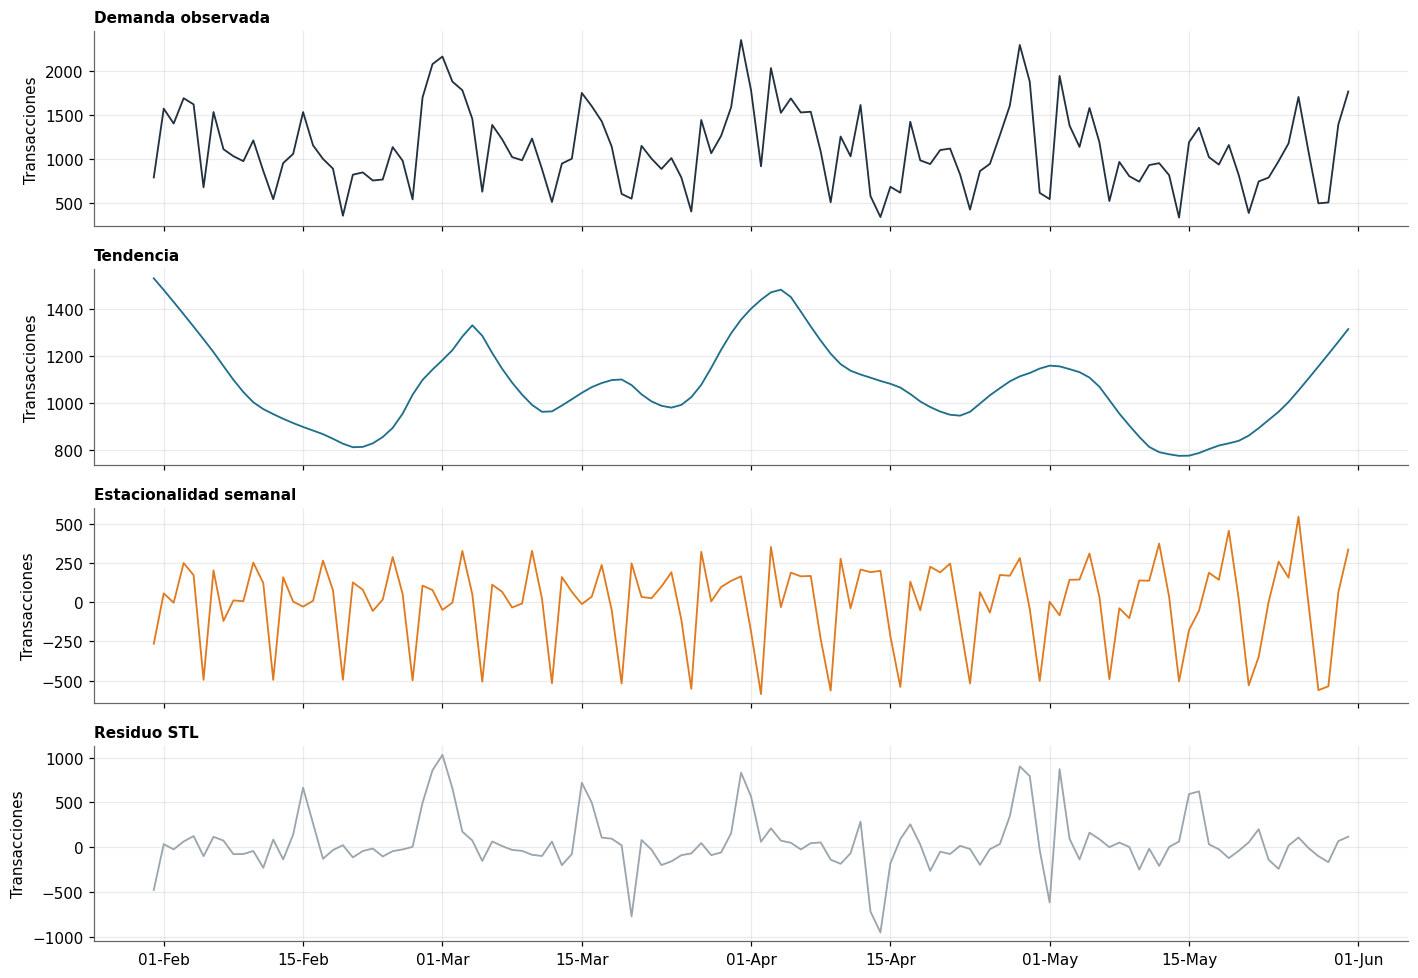

Lambda Box-Cox MLE sobre y + 1: 0.44 (1 ≈ sin transformación; 0 ≈ log)


In [12]:
from scipy.stats import boxcox_normmax
from statsmodels.tsa.seasonal import STL

SERIE_SEL = (df[df.idTerminal.isin(TERM) & df.oper.isin(OPS)]
             .groupby('d').size().reindex(ALL_DAYS, fill_value=0).astype(float))
print(f'25 series agregadas: {len(SERIE_SEL)} días | {SERIE_SEL.index.min():%Y-%m-%d} a {SERIE_SEL.index.max():%Y-%m-%d} | días con cero transacciones: {(SERIE_SEL == 0).sum()}')

stl_sel = STL(SERIE_SEL, period=7, robust=True).fit()
fig, axs = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, values, title, color in zip(
    axs,
    [SERIE_SEL, stl_sel.trend, stl_sel.seasonal, stl_sel.resid],
    ['Demanda observada', 'Tendencia', 'Estacionalidad semanal', 'Residuo STL'],
    [DK, ACC, '#E07A1F', GRY]
):
    ax.plot(values.index, values.values, color=color, lw=1.2)
    ax.set_ylabel('Transacciones')
    ax.set_title(title, loc='left', fontsize=10)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
plt.tight_layout(); save('fig_stl_semanal'); plt.show()

lambda_bc = boxcox_normmax(SERIE_SEL + 1, method='mle')
print(f'Lambda Box-Cox MLE sobre y + 1: {lambda_bc:.2f} (1 ≈ sin transformación; 0 ≈ log)')

**Identificación Box–Jenkins.** ADF tiene como hipótesis nula una raíz unitaria; KPSS, estacionariedad. Se leen conjuntamente: si ADF rechaza la raíz unitaria y KPSS no rechaza estacionariedad, se modela sin diferenciar (`d=D=0`). La diferencia semanal se conserva como diagnóstico de sensibilidad; ACF/PACF de la serie estacionaria orientan los órdenes AR y MA. Los días de pago y festivos son efectos de calendario que un SARIMA univariado no explica por sí solo.

Original                       | p-valor ADF: 0.0003 | p-valor KPSS: 0.1000
Diferencia semanal (lag 7)     | p-valor ADF: 0.0005 | p-valor KPSS: 0.1000


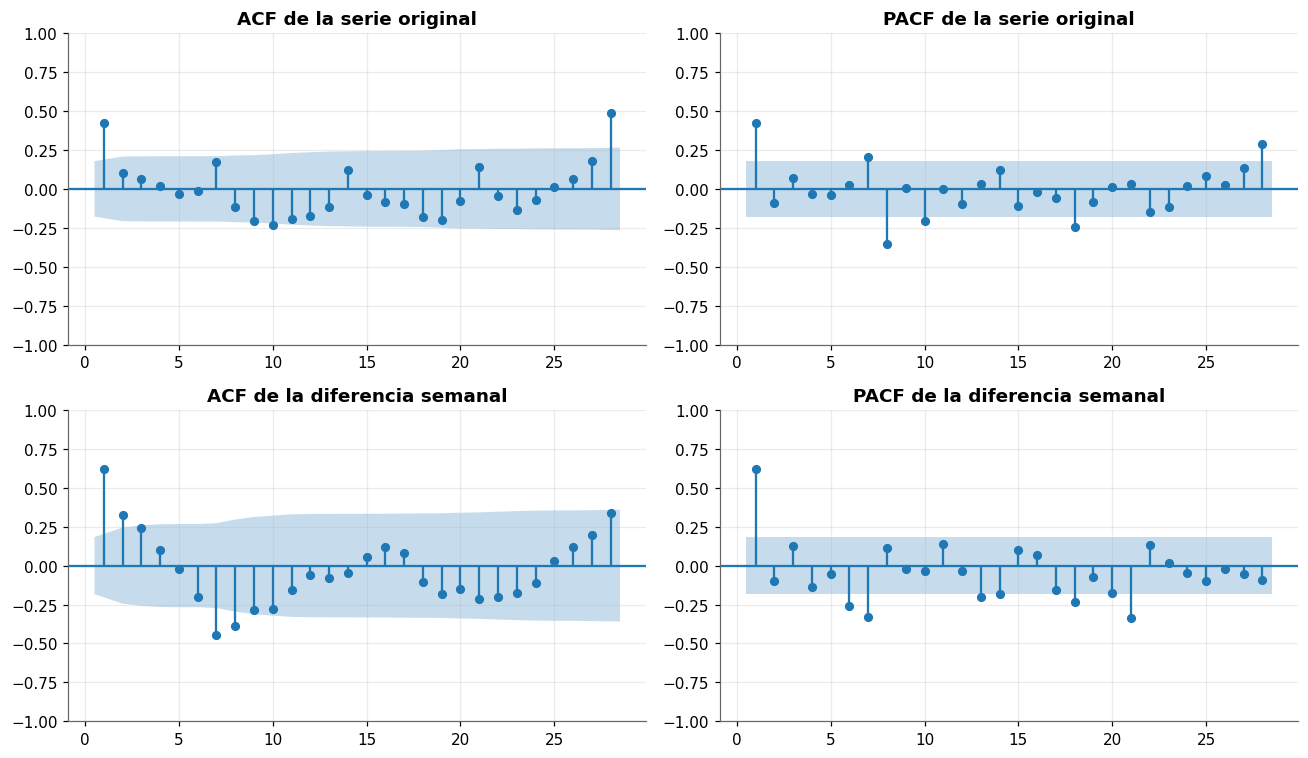

In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

serie_diff7 = SERIE_SEL.diff(7).dropna()
for label, values in [('Original', SERIE_SEL), ('Diferencia semanal (lag 7)', serie_diff7)]:
    adf_p = adfuller(values, autolag='AIC')[1]
    kpss_p = kpss(values, regression='c', nlags='auto')[1]
    print(f'{label:30s} | p-valor ADF: {adf_p:.4f} | p-valor KPSS: {kpss_p:.4f}')

fig, axs = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(SERIE_SEL, lags=28, ax=axs[0, 0], zero=False)
plot_pacf(SERIE_SEL, lags=28, ax=axs[0, 1], zero=False, method='ywm')
plot_acf(serie_diff7, lags=28, ax=axs[1, 0], zero=False)
plot_pacf(serie_diff7, lags=28, ax=axs[1, 1], zero=False, method='ywm')
axs[0, 0].set_title('ACF de la serie original')
axs[0, 1].set_title('PACF de la serie original')
axs[1, 0].set_title('ACF de la diferencia semanal')
axs[1, 1].set_title('PACF de la diferencia semanal')
plt.tight_layout(); save('fig_acf_pacf_semanal'); plt.show()

## 4. Modelo predictivo
### 4.1 Panel de series y variables
Se construye un panel *terminal × operación × día* con ceros explícitos. Todas las variables explicativas son **conocidas de antemano** para el horizonte de 15 días (calendario), por lo que el pronóstico es *directo* (sin recursión ni rezagos del propio target):
- día de la semana, día del mes, festivo, post-festivo;
- día de pago, días hábiles desde el último pago y hasta el próximo;
- nivel de la serie (media de entrenamiento) y código de operación.

**Por qué no usar rezagos:** con un horizonte de 15 días y solo 121 días de historia, rezagos ≥15 días consumirían >12 % de la muestra y aportan poco frente al calendario.

In [14]:
keep_terms = list(full.index)   # 44 terminales con cobertura completa (para el chequeo de robustez)
idx = pd.MultiIndex.from_product([keep_terms, OPS, ALL_DAYS], names=['t', 'o', 'd'])
P = (df[df.oper.isin(OPS) & df.idTerminal.isin(keep_terms)].groupby(['idTerminal', 'oper', 'd']).size()
     .reindex(idx, fill_value=0).rename('y').reset_index().merge(CAL, on='d'))
P['sid'] = P.t.astype(str) + '_' + P.o.astype(str)
P['bds'] = P.bd_since.clip(upper=3); P['bdt'] = P.bd_to.clip(upper=5)
SEL = [f'{t}_{o}' for t in TERM for o in OPS]
print('Panel:', P.shape, '| series seleccionadas:', len(SEL), '| series del chequeo de robustez:', P.sid.nunique())
zero_share = (P[P.sid.isin(SEL)].y == 0).mean(); print(f'Proporción de ceros en las 25 series: {zero_share:.1%}')

Panel: (26620, 14) | series seleccionadas: 25 | series del chequeo de robustez: 220
Proporción de ceros en las 25 series: 1.3%


### 4.2 Modelos candidatos
| Modelo | Idea | Motivo |
|---|---|---|
| **Naive estacional (t-7)** | Valor del mismo día de la semana anterior | Piso de comparación mínimo |
| **Media por día de la semana (últimas 4 sem., sin festivos)** | Perfil semanal reciente por serie | Baseline fuerte y explicable; ignora quincena |
| **GLM Poisson** | log(μ) = nivel de la serie + día de semana + quincena + festivo | Multiplicativo, apto para conteos, pocos parámetros, interpretable |
| **LightGBM Poisson (pooled)** | Árboles sobre calendario, entrenado con las 44×5 series de cobertura completa, objetivo = y / nivel | Captura interacciones (p. ej. quincena × día de la semana) y comparte información entre series |
| **Ensamble GLM + LightGBM** | Promedio de ambos | Reduce varianza; se equivocan de forma distinta |
| **Ensamble final (GLM + LightGBM + media semanal)** | Promedio de los tres | La media semanal reciente aporta el *nivel actual* de cada serie; GLM y LightGBM aportan la forma por quincena. *Nota: esta variante se eligió observando los mismos backtests, por lo que su ventaja puede estar ligeramente sobrestimada.* |

**No se usaron** ARIMA/SARIMA/Prophet por serie: con 121 días solo hay ≈17 ciclos semanales y 4–5 quincenas; SARIMA no incorpora el calendario de pagos y tiende a sobreajustar. Tampoco redes neuronales (volumen de datos insuficiente).

In [15]:
def glm_design(d):
    Z = pd.get_dummies(d.sid.astype(str), dtype=float)
    D = pd.get_dummies(d.dow.astype(str), prefix='dow', dtype=float).drop(columns='dow_0')
    B = pd.get_dummies(d.bds.astype(str), prefix='bds', dtype=float).drop(columns='bds_3', errors='ignore')
    T = pd.get_dummies(d.bdt.astype(str), prefix='bdt', dtype=float).drop(columns='bdt_5', errors='ignore')
    return pd.concat([Z, D, B, T, d[['hol']].astype(float)], axis=1)

def m_glm(tr, te):
    both = pd.concat([tr, te]); X = glm_design(both).astype(float)
    Xtr, Xte = X.iloc[:len(tr)], X.iloc[len(tr):]
    keep = Xtr.columns[Xtr.abs().sum() > 0]
    mod = sm.GLM(tr.y.values, Xtr[keep], family=sm.families.Poisson()).fit(maxiter=100)
    return mod.predict(Xte[keep]).values

LGB_FEATS = ['dow', 'dom', 'hol', 'bd_since', 'bd_to', 'is_pay', 'post_hol', 'o']
def m_lgb(tr, te):
    lvl = tr.groupby('sid').y.mean(); T = tr.copy(); T['lvl'] = T.sid.map(lvl).clip(lower=.05); T['rel'] = T.y / T.lvl
    mod = lgb.LGBMRegressor(objective='poisson', n_estimators=300, learning_rate=.03, num_leaves=8, min_child_samples=30,
                            subsample=.8, subsample_freq=1, colsample_bytree=.8, verbose=-1, random_state=0)
    mod.fit(T[LGB_FEATS], T.rel, sample_weight=T.lvl)
    return mod.predict(te[LGB_FEATS]) * te.sid.map(lvl).values

def m_snaive(tr, te):
    last = tr.d.max(); h = tr.set_index(['sid', 'd']).y
    out = []
    for s, d in zip(te.sid, te.d):
        k = int(np.ceil((d - last).days / 7)); out.append(h.get((s, d - pd.Timedelta(days=7 * k)), np.nan))
    return np.array(out)

def m_dowmean(tr, te):
    h = tr[(tr.d > tr.d.max() - pd.Timedelta(days=28)) & (tr.hol == 0)].groupby(['sid', 'dow']).y.mean()   # excluye festivos
    return np.array([h.get((s, w), np.nan) for s, w in zip(te.sid, te.dow)])

FINAL = 'Ensamble final (GLM+LGB+Media)'

def predict_all(train, test):
    """train/test: paneles completos (44x5 series). Devuelve dict de predicciones alineadas con test."""
    out = {'Naive t-7': m_snaive(train, test), 'Media día-semana (4 sem.)': m_dowmean(train, test)}
    out['GLM Poisson'] = m_glm(train, test); out['LightGBM pooled'] = m_lgb(train, test)
    out['Ensamble GLM+LGB'] = (out['GLM Poisson'] + out['LightGBM pooled']) / 2
    out[FINAL] = (out['GLM Poisson'] + out['LightGBM pooled'] + out['Media día-semana (4 sem.)']) / 3
    return out

### 4.3 Validación: *backtesting* con origen móvil
Se simula 4 veces el uso real: entrenar con datos hasta un corte y predecir los **15 días siguientes**, sin ver el futuro. Los cortes (15-abr, 30-abr, 15-may y 31-may) cubren distintas posiciones del ciclo de quincena. **Importante:** los GLM de cada corte se ajustan solo con las 25 series seleccionadas; LightGBM aprende de las 220 series (44 terminales × 5 ops).

Métricas (sobre las 25 series seleccionadas):
- **WAPE** = Σ|y − ŷ| / Σy → error porcentual ponderado por volumen (robusto a ceros, preferido sobre MAPE).
- **MAE / RMSE** en transacciones por serie-día.
- **Sesgo** = (Σŷ − Σy)/Σy.
- **WAPE a 15 días** = error del *total* de la ventana por serie (lo que importa para planificar capacidad).

In [16]:
FOLDS = [('2017-03-31', '2017-04-01', '2017-04-15'), ('2017-04-15', '2017-04-16', '2017-04-30'),
         ('2017-04-30', '2017-05-01', '2017-05-15'), ('2017-05-16', '2017-05-17', '2017-05-31')]
bt = []   # predicciones por fold
for tr_end, te_s, te_e in FOLDS:
    train = P[P.d <= tr_end].reset_index(drop=True); test = P[(P.d >= te_s) & (P.d <= te_e)].reset_index(drop=True)
    preds = predict_all(train, test)
    for k, v in preds.items(): test[k] = v
    test['fold'] = f'{te_s[5:]}→{te_e[5:]}'; bt.append(test)
BT = pd.concat(bt, ignore_index=True)
MODELS = ['Naive t-7', 'Media día-semana (4 sem.)', 'GLM Poisson', 'LightGBM pooled', 'Ensamble GLM+LGB', FINAL]

def metrics(g, m):
    s = g[g.sid.isin(SEL)]; e = s.y - s[m]
    tot = s.groupby(['sid', 'fold'])[['y', m]].sum()
    return pd.Series({'WAPE diario': e.abs().sum() / s.y.sum(), 'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean()),
                      'Sesgo': (s[m].sum() - s.y.sum()) / s.y.sum(), 'WAPE 15 días': (tot.y - tot[m]).abs().sum() / tot.y.sum()})
res = pd.DataFrame({m: metrics(BT, m) for m in MODELS}).T
print('Desempeño promedio sobre los 4 backtests (25 series):'); print(res.round(3).to_string())
by_fold = pd.DataFrame({m: {f: metrics(BT[BT.fold == f], m)['WAPE diario'] for f in BT.fold.unique()} for m in MODELS})
print('\nWAPE diario por ventana de prueba:'); print(by_fold.round(3).to_string())

Desempeño promedio sobre los 4 backtests (25 series):
                                WAPE diario     MAE    RMSE  Sesgo  WAPE 15 días
Naive t-7                             0.554  24.023  45.329 -0.011         0.225
Media día-semana (4 sem.)             0.416  18.037  31.625  0.083         0.139
GLM Poisson                           0.365  15.831  27.281  0.024         0.143
LightGBM pooled                       0.352  15.282  27.666  0.031         0.159
Ensamble GLM+LGB                      0.347  15.060  26.385  0.027         0.144
Ensamble final (GLM+LGB+Media)        0.345  14.959  26.134  0.046         0.131

WAPE diario por ventana de prueba:
             Naive t-7  Media día-semana (4 sem.)  GLM Poisson  LightGBM pooled  Ensamble GLM+LGB  Ensamble final (GLM+LGB+Media)
04-01→04-15      0.550                      0.421        0.329            0.393             0.350                           0.345
04-16→04-30      0.536                      0.398        0.346            0.317    

### 4.3b Benchmark Box–Jenkins: ARIMAX con calendario

Se adapta el flujo del script R —estacionariedad, ACF/PACF, transformación Box–Cox, selección por información y diagnóstico de residuos— a `statsmodels`. ADF/KPSS indican que la serie agregada es estacionaria, por lo que se mantiene `d=0`. El patrón semanal se representa con efectos de día de semana conocidos, junto con festivos y días de pago; se seleccionan errores ARMA acotados por AIC. En cada ventana Box–Cox y el ajuste se estiman solo con el entrenamiento. La comparación es sobre el agregado de las mismas 25 series, no sobre cada combinación por separado. El PDF de manchas solares y los órdenes concretos de ese ejemplo no se trasladan: la frecuencia y el mecanismo de esta serie son distintos.

Candidatos descartados por no converger en 04-01→04-15: [(1, 0, 0), (1, 0, 1)]
Candidatos descartados por no converger en 04-16→04-30: [(1, 0, 0), (1, 0, 1)]
Candidatos descartados por no converger en 05-01→05-15: [(1, 0, 0), (1, 0, 1)]
Candidatos descartados por no converger en 05-17→05-31: [(1, 0, 0), (1, 0, 1)]
Backtesting agregado de 25 series (4 ventanas de 15 días):
                     WAPE      MAE     RMSE  Sesgo
ARIMAX Box–Cox      0.246  266.928  331.314  0.009
Ensamble por serie  0.229  247.885  304.110  0.046

Órdenes y lambda elegidos por ventana:
                 orden  lambda_bc
fold                             
04-01→04-15  (0, 0, 1)   0.393659
04-16→04-30  (0, 0, 1)   0.527747
05-01→05-15  (0, 0, 1)   0.447896
05-17→05-31  (0, 0, 1)   0.455170

Modelo final: ARIMAX(1, 0, 0) | lambda=0.44 | AIC=708.7 | BIC=739.3
Candidatos descartados por no converger en el ajuste final: [(1, 0, 1)]
            pronostico  li80  ls80
d                                 
2017-06-01       

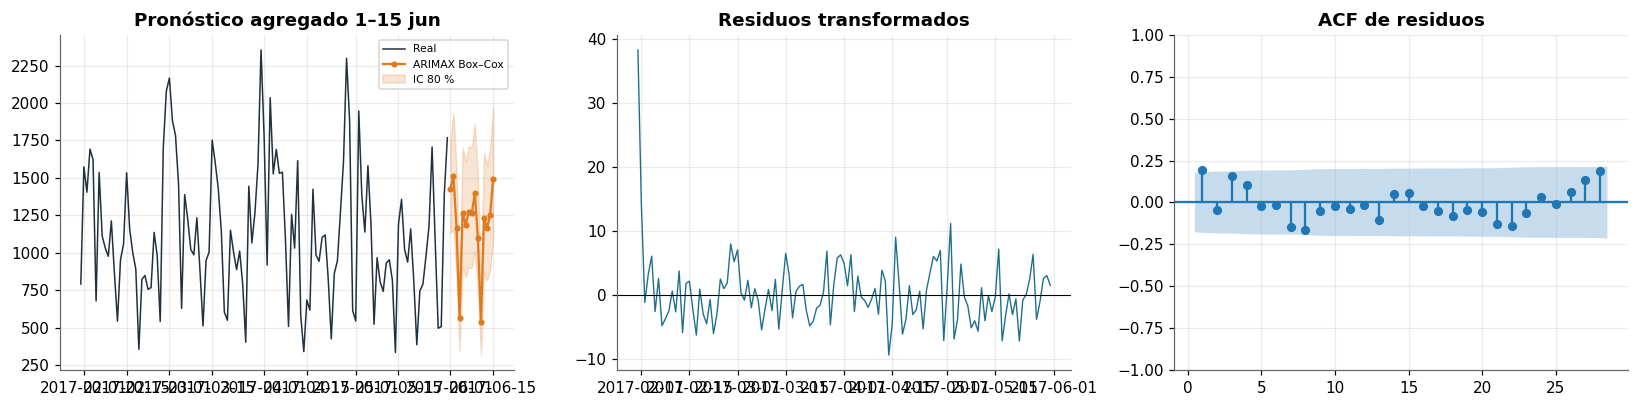

In [17]:
from scipy.special import inv_boxcox
from scipy.stats import boxcox, boxcox_normmax
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX

CAL_BJ = CAL.set_index('d')
BJ_DOW = pd.get_dummies(CAL_BJ.dow.astype(str), prefix='dow', dtype=float).drop(columns='dow_0')
BJ_EXOG = pd.concat([BJ_DOW, CAL_BJ[['hol', 'is_pay']].astype(float)], axis=1)
BJ_ORDERS = [(0, 0, 0), (1, 0, 0), (0, 0, 1), (1, 0, 1)]

def seleccionar_arimax(y_train):
    lambda_train = boxcox_normmax(y_train + 1, method='mle')
    y_transformada = pd.Series(boxcox(y_train + 1, lmbda=lambda_train), index=y_train.index)
    candidatos, no_convergieron = [], []
    for order in BJ_ORDERS:
        ajuste = SARIMAX(
            y_transformada, exog=BJ_EXOG.loc[y_train.index], order=order,
            trend='c', enforce_stationarity=False, enforce_invertibility=False
        ).fit(disp=False, maxiter=150)
        if ajuste.mle_retvals.get('converged', True) and np.isfinite(ajuste.aic):
            candidatos.append(ajuste)
        else:
            no_convergieron.append(order)
    if not candidatos:
        raise RuntimeError('Ningún candidato ARIMAX convergió; revise la serie y los órdenes.')
    return min(candidatos, key=lambda ajuste: ajuste.aic), lambda_train, no_convergieron

bj_bt = []
for tr_end, te_s, te_e in FOLDS:
    y_train = SERIE_SEL.loc[:tr_end]
    y_test = SERIE_SEL.loc[te_s:te_e]
    ajuste, lambda_train, no_convergieron = seleccionar_arimax(y_train)
    pred_t = ajuste.get_forecast(steps=len(y_test), exog=BJ_EXOG.loc[y_test.index]).predicted_mean
    pred = np.maximum(inv_boxcox(pred_t, lambda_train) - 1, 0)
    fold = f'{te_s[5:]}→{te_e[5:]}'
    bj_bt.append(pd.DataFrame({'d': y_test.index, 'y': y_test.values, 'ARIMAX': pred,
                               'fold': fold, 'lambda': lambda_train,
                               'orden': [str(ajuste.model.order)] * len(y_test)}))
    if no_convergieron:
        print(f'Candidatos descartados por no converger en {fold}: {no_convergieron}')
BJ_BT = pd.concat(bj_bt, ignore_index=True)

ensamble_total = (BT[BT.sid.isin(SEL)].groupby(['fold', 'd'])
                  .agg(real=('y', 'sum'), Ensamble=(FINAL, 'sum')).reset_index())
comparacion_bj = BJ_BT.merge(ensamble_total, on=['fold', 'd'], validate='one_to_one')
def metricas_agregado(real, pred):
    error = real - pred
    return {'WAPE': error.abs().sum() / real.sum(), 'MAE': error.abs().mean(),
            'RMSE': np.sqrt((error ** 2).mean()), 'Sesgo': (pred.sum() - real.sum()) / real.sum()}

metricas_bj = pd.DataFrame({
    'ARIMAX Box–Cox': metricas_agregado(comparacion_bj.real, comparacion_bj.ARIMAX),
    'Ensamble por serie': metricas_agregado(comparacion_bj.real, comparacion_bj.Ensamble)
}).T
print('Backtesting agregado de 25 series (4 ventanas de 15 días):')
print(metricas_bj.round(3).to_string())
print('\nÓrdenes y lambda elegidos por ventana:')
print(BJ_BT.groupby('fold').agg(orden=('orden', 'first'), lambda_bc=('lambda', 'first')).to_string())

bj_final, lambda_final, no_convergieron = seleccionar_arimax(SERIE_SEL)
BJ_FUT = pd.date_range('2017-06-01', '2017-06-15', name='d')
bj_fc = bj_final.get_forecast(steps=len(BJ_FUT), exog=BJ_EXOG.loc[BJ_FUT])
bj_ci_t = bj_fc.conf_int(alpha=0.20)
BJ_FORECAST = pd.DataFrame({
    'pronostico': np.maximum(inv_boxcox(bj_fc.predicted_mean, lambda_final) - 1, 0),
    'li80': np.maximum(inv_boxcox(bj_ci_t.iloc[:, 0], lambda_final) - 1, 0),
    'ls80': np.maximum(inv_boxcox(bj_ci_t.iloc[:, 1], lambda_final) - 1, 0)
}, index=BJ_FUT)
print(f'\nModelo final: ARIMAX{bj_final.model.order} | lambda={lambda_final:.2f} | AIC={bj_final.aic:.1f} | BIC={bj_final.bic:.1f}')
if no_convergieron:
    print('Candidatos descartados por no converger en el ajuste final:', no_convergieron)
print(BJ_FORECAST.round(0).astype(int).to_string())

resid_bj = pd.Series(bj_final.resid, index=SERIE_SEL.index).dropna()
df_modelo = sum(bj_final.model.order)
lb_bj = acorr_ljungbox(resid_bj, lags=[7, 14], model_df=df_modelo, return_df=True)
print('\nLjung–Box de residuos transformados (p pequeño sugiere autocorrelación pendiente):')
print(lb_bj[['lb_stat', 'lb_pvalue']].round(4).to_string())

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].plot(SERIE_SEL.index, SERIE_SEL, color=DK, lw=1, label='Real')
axs[0].plot(BJ_FORECAST.index, BJ_FORECAST.pronostico, color='#E07A1F', marker='o', ms=3, label='ARIMAX Box–Cox')
axs[0].fill_between(BJ_FORECAST.index, BJ_FORECAST.li80, BJ_FORECAST.ls80, color='#E07A1F', alpha=.2, label='IC 80 %')
axs[0].set_title('Pronóstico agregado 1–15 jun'); axs[0].legend(fontsize=7)
axs[1].plot(resid_bj.index, resid_bj, color=ACC, lw=.9); axs[1].axhline(0, color='k', lw=.7)
axs[1].set_title('Residuos transformados')
plot_acf(resid_bj, lags=28, ax=axs[2], zero=False); axs[2].set_title('ACF de residuos')
plt.tight_layout(); save('fig_diagnostico_box_jenkins'); plt.show()

**Interpretación y decisión.** El AIC identifica candidatos dentro de cada entrenamiento, pero la selección final se decide por el backtesting de 15 días. El contraste de Ljung–Box y la ACF residual verifican si queda autocorrelación: un p-valor pequeño indica que el modelo aún no captura toda la dinámica. Este benchmark predice el total de las 25 series; no sustituye el ensamble cuando se necesita pronóstico por terminal y operación.

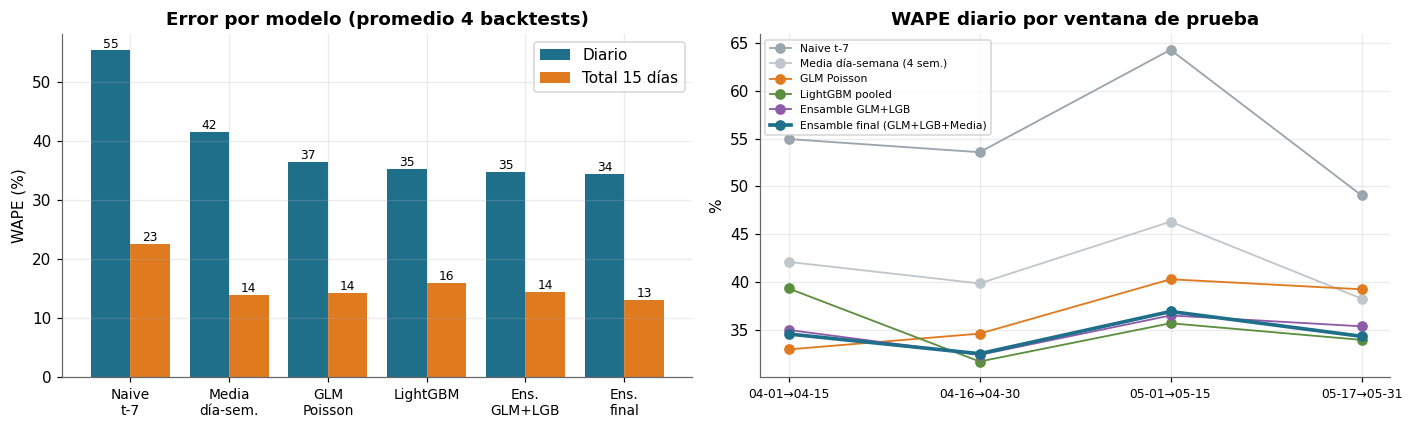

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(MODELS)); axs[0].bar(x - .2, res['WAPE diario'] * 100, .4, color=ACC, label='Diario'); axs[0].bar(x + .2, res['WAPE 15 días'] * 100, .4, color='#E07A1F', label='Total 15 días')
axs[0].set_xticks(x); axs[0].set_xticklabels(['Naive\nt-7', 'Media\ndía-sem.', 'GLM\nPoisson', 'LightGBM', 'Ens.\nGLM+LGB', 'Ens.\nfinal'], fontsize=9); axs[0].set_ylabel('WAPE (%)'); axs[0].legend(); axs[0].set_title('Error por modelo (promedio 4 backtests)')
for i, v in enumerate(res['WAPE diario'] * 100): axs[0].text(i - .2, v + .5, f'{v:.0f}', ha='center', fontsize=8)
for i, v in enumerate(res['WAPE 15 días'] * 100): axs[0].text(i + .2, v + .5, f'{v:.0f}', ha='center', fontsize=8)
for m, c in zip(MODELS, [GRY, '#C0C7CC', PAL[1], PAL[2], PAL[3], ACC]): axs[1].plot(by_fold.index, by_fold[m] * 100, marker='o', label=m, color=c, lw=2.4 if m == FINAL else 1.2)
axs[1].set_title('WAPE diario por ventana de prueba'); axs[1].set_ylabel('%'); axs[1].legend(fontsize=7); axs[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); save('fig_backtest'); plt.show()

**Lectura.**
- Los modelos con calendario (GLM, LightGBM y los ensambles) reducen el **error diario de ~55 % (naive t-7) y ~42 % (media semanal) a ~35 %**; el **ensamble final** es el mejor o casi el mejor en las 4 ventanas (WAPE 33–37 %), con un sesgo moderado (+5 %, ligera sobreestimación).
- Para el **total de 15 días por serie** la diferencia es menor: la media semanal reciente ya acierta bien el *nivel* (WAPE ≈14 %) porque la ventana de 15 días siempre contiene una quincena; el ensamble final queda en ≈13 %, un empate práctico. Los modelos de calendario aportan sobre todo **la forma diaria** (cuándo caen los picos y valles).
- El error diario (~35 %) es alto; abajo se descompone cuánto es ruido aleatorio y cuánto efecto de festivos y eventos por terminal.

In [19]:
# Piso teórico de ruido Poisson: E|y-μ| ≈ √(2μ/π) para μ grande; se evalúa con las predicciones del ensamble como μ
s = BT[BT.sid.isin(SEL)]
floor = np.sqrt(2 * s[FINAL].clip(lower=.1) / np.pi).sum() / s.y.sum()
print(f'Piso aproximado de WAPE por ruido de Poisson puro: {floor:.1%}  vs. WAPE observado del ensamble: {res.loc[FINAL, "WAPE diario"]:.1%}')
print('→ El ruido Poisson explica solo una fracción del error: el resto es variabilidad extra (festivos y eventos específicos de terminal, ver 4.3b).')
# Desempeño por operación y terminal
for key, name in [('o', 'operación'), ('t', 'terminal')]:
    g = s.groupby(key).apply(lambda z: pd.Series({'WAPE diario': (z.y - z[FINAL]).abs().sum() / z.y.sum(), 'tx/día prom.': z.y.mean()}))
    print(f'\nWAPE del ensamble por {name}:'); print(g.round(3).to_string())

Piso aproximado de WAPE por ruido de Poisson puro: 10.9%  vs. WAPE observado del ensamble: 34.5%
→ El ruido Poisson explica solo una fracción del error: el resto es variabilidad extra (festivos y eventos específicos de terminal, ver 4.3b).

WAPE del ensamble por operación:
   WAPE diario  tx/día prom.
o                           
0        0.316       126.007
1        0.370        23.963
3        0.353        42.807
4        0.588         9.960
7        0.366        14.080

WAPE del ensamble por terminal:
      WAPE diario  tx/día prom.
t                              
1774        0.371        49.737
1908        0.383        43.983
1910        0.314        44.007
1964        0.362        41.467
1980        0.284        37.623


### 4.3b ¿Dónde se equivoca el modelo?

In [20]:
s = BT[BT.sid.isin(SEL)].copy(); s['e'] = s.y - s[FINAL]
hm_ = s.hol == 1
print(f'WAPE en días NO festivos: {s[~hm_].e.abs().sum() / s[~hm_].y.sum():.1%} | en festivos: {s[hm_].e.abs().sum() / s[hm_].y.sum():.1%}')
by_day = s.groupby('d').agg(y=('y', 'sum'), p=(FINAL, 'sum')); by_day['error_%'] = (by_day.y / by_day.p - 1) * 100
print('\nDías con mayor sobrestimación (real < pronóstico):'); print(by_day.sort_values('error_%').head(5).round(0).to_string())
td = s.groupby(['t', 'd']).agg(y=('y', 'sum'), p=(FINAL, 'sum')); td['ratio'] = td.y / td.p
low = td[td.ratio < .5]
print(f'\nTerminal-días con volumen < 50 % de lo esperado: {len(low)} de {len(td)} ({len(low) / len(td):.0%}); de ellos {low.reset_index().d.isin(HOL).sum() + low.reset_index().d.dt.dayofweek.isin([5, 6]).sum()} caen en festivo o fin de semana')
print(low[~low.reset_index().d.isin(HOL).values & (low.reset_index().d.dt.dayofweek < 5).values].round(2).to_string())

WAPE en días NO festivos: 32.3% | en festivos: 105.1%

Días con mayor sobrestimación (real < pronóstico):
              y       p  error_%
d                               
2017-04-14  340  1177.0    -71.0
2017-04-15  684  1326.0    -48.0
2017-04-13  579  1024.0    -43.0
2017-05-01  544   917.0    -41.0
2017-05-10  742  1192.0    -38.0

Terminal-días con volumen < 50 % de lo esperado: 25 de 300 (8%); de ellos 19 caen en festivo o fin de semana
                   y       p  ratio
t    d                             
1774 2017-05-12   80  336.41   0.24
1908 2017-05-12  133  317.17   0.42
     2017-05-23  110  227.85   0.48
1964 2017-05-03  122  321.93   0.38
     2017-05-04    0  264.50   0.00
     2017-05-30   62  279.37   0.22


**Lectura.** (1) Los **festivos son la mayor fuente de error** (el modelo solo vio un festivo en la primera ventana de entrenamiento; en Semana Santa, 13–15 abr, el real quedó entre 43 % y 71 % por debajo del pronóstico). Como la ventana de pronóstico (1–15 jun) **no contiene festivos**, el error relevante es el de días no festivos (≈32 %). (2) De los terminal-días con volumen < 50 % de lo esperado (8 %), la mayoría son fines de semana o festivos, pero **6 ocurren en días hábiles normales** (p. ej. 1964 el 4-may con 0 transacciones; 1774 el 12-may con 24 % de lo esperado): posibles fallas o indisponibilidad. Un modelo calendario no puede anticiparlas, pero sí **detectarlas** comparando real vs. pronóstico — un uso directo para la entidad.

### 4.4 ¿Qué tan válido es el modelo? Diagnóstico
1. **Contra baselines:** supera a los dos baselines en el error diario en las 4 ventanas; en el total de 15 días la ventaja es menor (ver 4.3).
2. **Sesgo:** moderado (≈+5 % en promedio: ligera sobreestimación, concentrada en festivos y días con volumen anormalmente bajo). Al planificar, las cifras de volumen deben leerse como un techo razonable.
3. **Calibración de intervalos:** se construyen intervalos del 80 % con residuos de Pearson estandarizados, (y−μ)/√μ. Se **calibra con las ventanas 1–3** y se **mide la cobertura en la ventana 4** (no vista).

Cuantiles z (10 %, 90 %) calibrados en ventanas 1–3: -3.40, 3.15 | Cobertura nominal 80 % → real en ventana 4: 84.5%
Desviación estándar de z (1 = Poisson puro): 2.83 → hay sobre-dispersión; justifica usar intervalos empíricos en vez de Poisson.


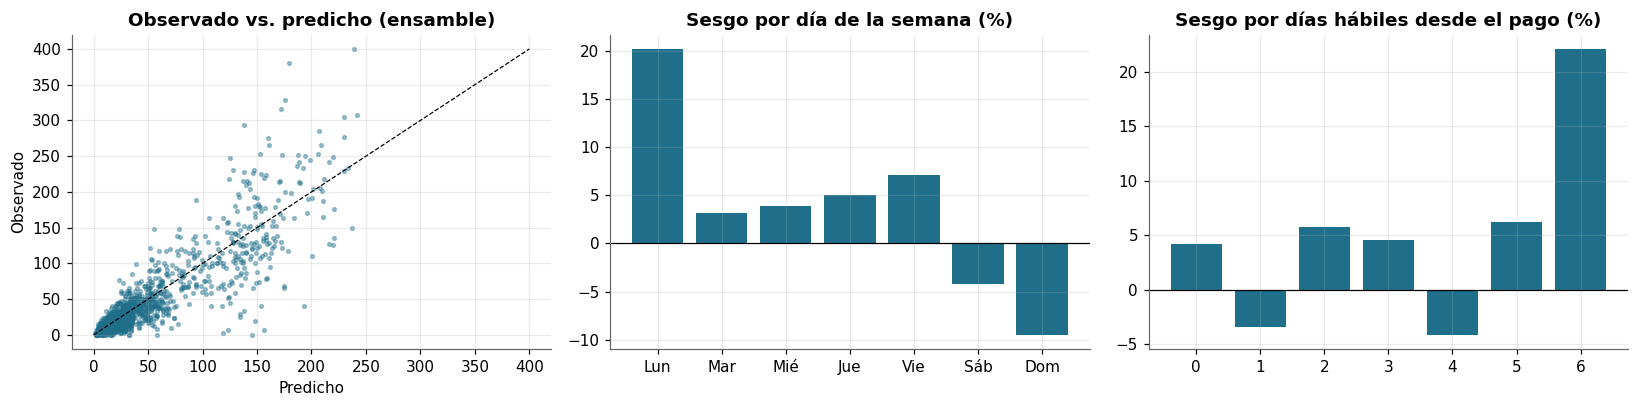

In [21]:
s = BT[BT.sid.isin(SEL)].copy(); s['mu'] = s[FINAL].clip(lower=.5); s['z'] = (s.y - s.mu) / np.sqrt(s.mu)
cal = s[s.fold != s.fold.unique()[-1]]; hold = s[s.fold == s.fold.unique()[-1]]
qlo, qhi = cal.z.quantile([.10, .90])
lo = (hold.mu + qlo * np.sqrt(hold.mu)).clip(lower=0); hi = hold.mu + qhi * np.sqrt(hold.mu)
cov = ((hold.y >= lo) & (hold.y <= hi)).mean()
print(f'Cuantiles z (10 %, 90 %) calibrados en ventanas 1–3: {qlo:.2f}, {qhi:.2f} | Cobertura nominal 80 % → real en ventana 4: {cov:.1%}')
print('Desviación estándar de z (1 = Poisson puro):', round(s.z.std(), 2), '→ hay sobre-dispersión; justifica usar intervalos empíricos en vez de Poisson.')

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].scatter(s.mu, s.y, s=6, alpha=.4, color=ACC); mx = s[['mu', 'y']].max().max(); axs[0].plot([0, mx], [0, mx], 'k--', lw=.8)
axs[0].set_xlabel('Predicho'); axs[0].set_ylabel('Observado'); axs[0].set_title('Observado vs. predicho (ensamble)')
b = s.groupby('dow').apply(lambda z: (z.mu.sum() - z.y.sum()) / z.y.sum()) * 100
axs[1].bar(dow_names, b.values, color=ACC); axs[1].axhline(0, color='k', lw=.8); axs[1].set_title('Sesgo por día de la semana (%)')
b2 = s.groupby('bd_since').apply(lambda z: (z.mu.sum() - z.y.sum()) / z.y.sum()).loc[0:6] * 100
axs[2].bar(b2.index.astype(str), b2.values, color=ACC); axs[2].axhline(0, color='k', lw=.8); axs[2].set_title('Sesgo por días hábiles desde el pago (%)')
plt.tight_layout(); save('fig_diag'); plt.show()

### 4.5 Robustez: ¿se sostiene el modelo en las 44 terminales × 5 operaciones?
Para no depender de la selección, se repiten los mismos backtests sobre **todas** las series con cobertura completa (220 series).

In [22]:
rob = []
for tr_end, te_s, te_e in FOLDS:
    train = P[P.d <= tr_end].reset_index(drop=True); test = P[(P.d >= te_s) & (P.d <= te_e)].reset_index(drop=True)
    pr = predict_all(train, test)
    for k, v in pr.items(): test[k] = v
    rob.append(test)
ROB = pd.concat(rob)
def wape(g, m): return (g.y - g[m]).abs().sum() / g.y.sum()
rt = pd.DataFrame({'WAPE diario (220 series)': {m: wape(ROB, m) for m in MODELS}})
print(rt.round(3).to_string())
ROB['mu'] = ROB[FINAL]
w_t = ROB.groupby('t').apply(lambda g: wape(g, FINAL))
tot = ROB.groupby(['t', 'd'])[['y', 'mu']].sum()
print(f'WAPE diario total por terminal (suma de las 5 ops), mediana: {((tot.y - tot.mu).abs().groupby("t").sum() / tot.y.groupby("t").sum()).median():.1%}')
print(f'WAPE diario del total de la entidad (44 terminales × 5 ops): {((ROB.groupby("d").y.sum() - ROB.groupby("d").mu.sum()).abs().sum() / ROB.y.sum()):.1%}')

                                WAPE diario (220 series)
Naive t-7                                          0.641
Media día-semana (4 sem.)                          0.476
GLM Poisson                                        0.393
LightGBM pooled                                    0.398
Ensamble GLM+LGB                                   0.386
Ensamble final (GLM+LGB+Media)                     0.393
WAPE diario total por terminal (suma de las 5 ops), mediana: 33.4%
WAPE diario del total de la entidad (44 terminales × 5 ops): 20.2%


**Conclusión de validez.** El modelo es **útil para estimar niveles y patrones** (picos de quincena, domingos) y para **totales agregados**: error ≈13 % en el total de 15 días por serie y ≈20 % en el volumen diario de toda la entidad (220 series), con sesgo moderado (+5 %). **No es fiable para el valor exacto de un día en una terminal-operación pequeña** (la operación 4, con ≈10 tx/día, tiene un WAPE diario ≈60 %), ni anticipa festivos nuevos ni fallas de terminal. Funciona mejor cuanto más agregado el nivel y cuanto mayor el volumen.

### 4.6 Calidad y cantidad de la información (punto 2a)
- **Calidad:** buena en consistencia (sin nulos ni duplicados), pero con (i) terminales que entran o salen, (ii) un código de operación sin diccionario, (iii) archivo desordenado y (iv) solo transacciones **realizadas** (no sabemos si hubo capacidad insuficiente o fallas: la demanda real puede ser mayor que la observada — *censura*).
- **Cantidad:** insuficiente para estacionalidad anual (4 meses): no se pueden aprender efectos de diciembre/prima, semana santa, etc. Hay solo 4–5 ciclos de quincena y 5 festivos, por lo que sus efectos se estiman con incertidumbre. La cantidad **sí alcanza** para patrón semanal y de quincena a nivel de las operaciones principales.
- **Qué mejoraría el modelo:** ≥12–24 meses de historia, diccionario de operaciones, estado/disponibilidad de la terminal, ubicación/tipo de punto, montos, y calendario de campañas.

## 5. Pronóstico 1–15 de junio de 2017
Se re-entrena el ensamble final con **todo el histórico** (hasta el 31-may) y se predice cada serie para los 15 días siguientes. Los festivos del 19 y 26-jun quedan fuera de la ventana; no hay festivos entre el 1 y el 15-jun. El 15-jun (jueves) es día de pago y el 1-jun es el día hábil posterior al pago del 31-may, ambos picos esperados.

In [23]:
FUT = pd.date_range('2017-06-01', '2017-06-15')
sel_ser = pd.MultiIndex.from_product([TERM, OPS], names=['t', 'o']).to_frame(index=False)
fut = sel_ser.merge(pd.DataFrame({'d': FUT}), how='cross').merge(CAL, on='d')
fut['sid'] = fut.t.astype(str) + '_' + fut.o.astype(str); fut['bds'] = fut.bd_since.clip(upper=3); fut['bdt'] = fut.bd_to.clip(upper=5); fut['y'] = np.nan
# Para el GLM se usa solo el panel seleccionado; para LGB, el panel completo
train_all = P.copy()
g = m_glm(P[P.sid.isin(SEL)].reset_index(drop=True), fut)
l = m_lgb(train_all, fut)
dm = m_dowmean(P[P.sid.isin(SEL)].reset_index(drop=True), fut)
fut['pred'] = (g + l + dm) / 3
fut['mu'] = fut.pred.clip(lower=.5)
# Intervalo 80 % con residuos de Pearson de TODAS las ventanas
zq = s.z.quantile([.10, .90]).values
fut['lo'] = (fut.mu + zq[0] * np.sqrt(fut.mu)).clip(lower=0); fut['hi'] = fut.mu + zq[1] * np.sqrt(fut.mu)
fut['dia'] = fut.d.dt.strftime('%a %d-%b')
out = fut[['d', 't', 'o', 'pred', 'lo', 'hi']].rename(columns={'d': 'fecha', 't': 'idTerminal', 'o': 'oper', 'pred': 'pronostico', 'lo': 'li80', 'hi': 'ls80'})
out[['pronostico', 'li80', 'ls80']] = out[['pronostico', 'li80', 'ls80']].round(1)
out.to_csv(f'{OUT}/pronostico_1_15_jun_2017.csv', index=False)
print('Archivo guardado:', f'{OUT}/pronostico_1_15_jun_2017.csv', out.shape)
tot15 = fut.groupby(['t', 'o']).pred.sum().unstack().round(0)
print('Pronóstico: total de transacciones 1–15 jun por terminal (filas) y operación (columnas):'); print(tot15.astype(int).to_string())
print('Total 25 series:', int(tot15.values.sum()))
hist15 = P[P.sid.isin(SEL) & (P.d >= '2017-05-17')].y.sum()
print(f'Referencia: real 17–31 may (15 días) en las mismas 25 series = {int(hist15):,} → variación pronosticada {tot15.values.sum() / hist15 - 1:+.1%}')

Archivo guardado: imagenes/pronostico_1_15_jun_2017.csv (375, 6)
Pronóstico: total de transacciones 1–15 jun por terminal (filas) y operación (columnas):
o        0    1    3    4    7
t                             
1774  2236  402  832  142  170
1908  1947  296  765  258  264
1910  2098  244  483  111  291
1964  1828  378  746  207  142
1980  1580  535  437   88  216
Total 25 series: 16696
Referencia: real 17–31 may (15 días) en las mismas 25 series = 14,963 → variación pronosticada +11.6%


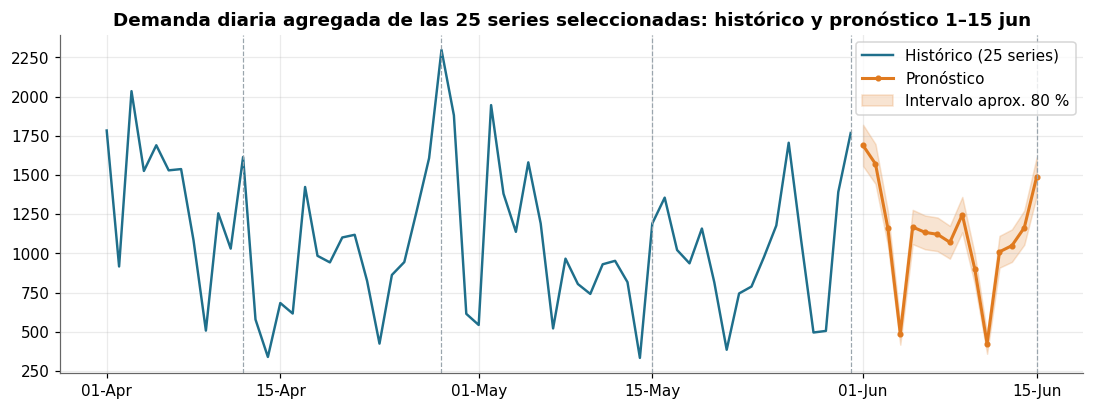

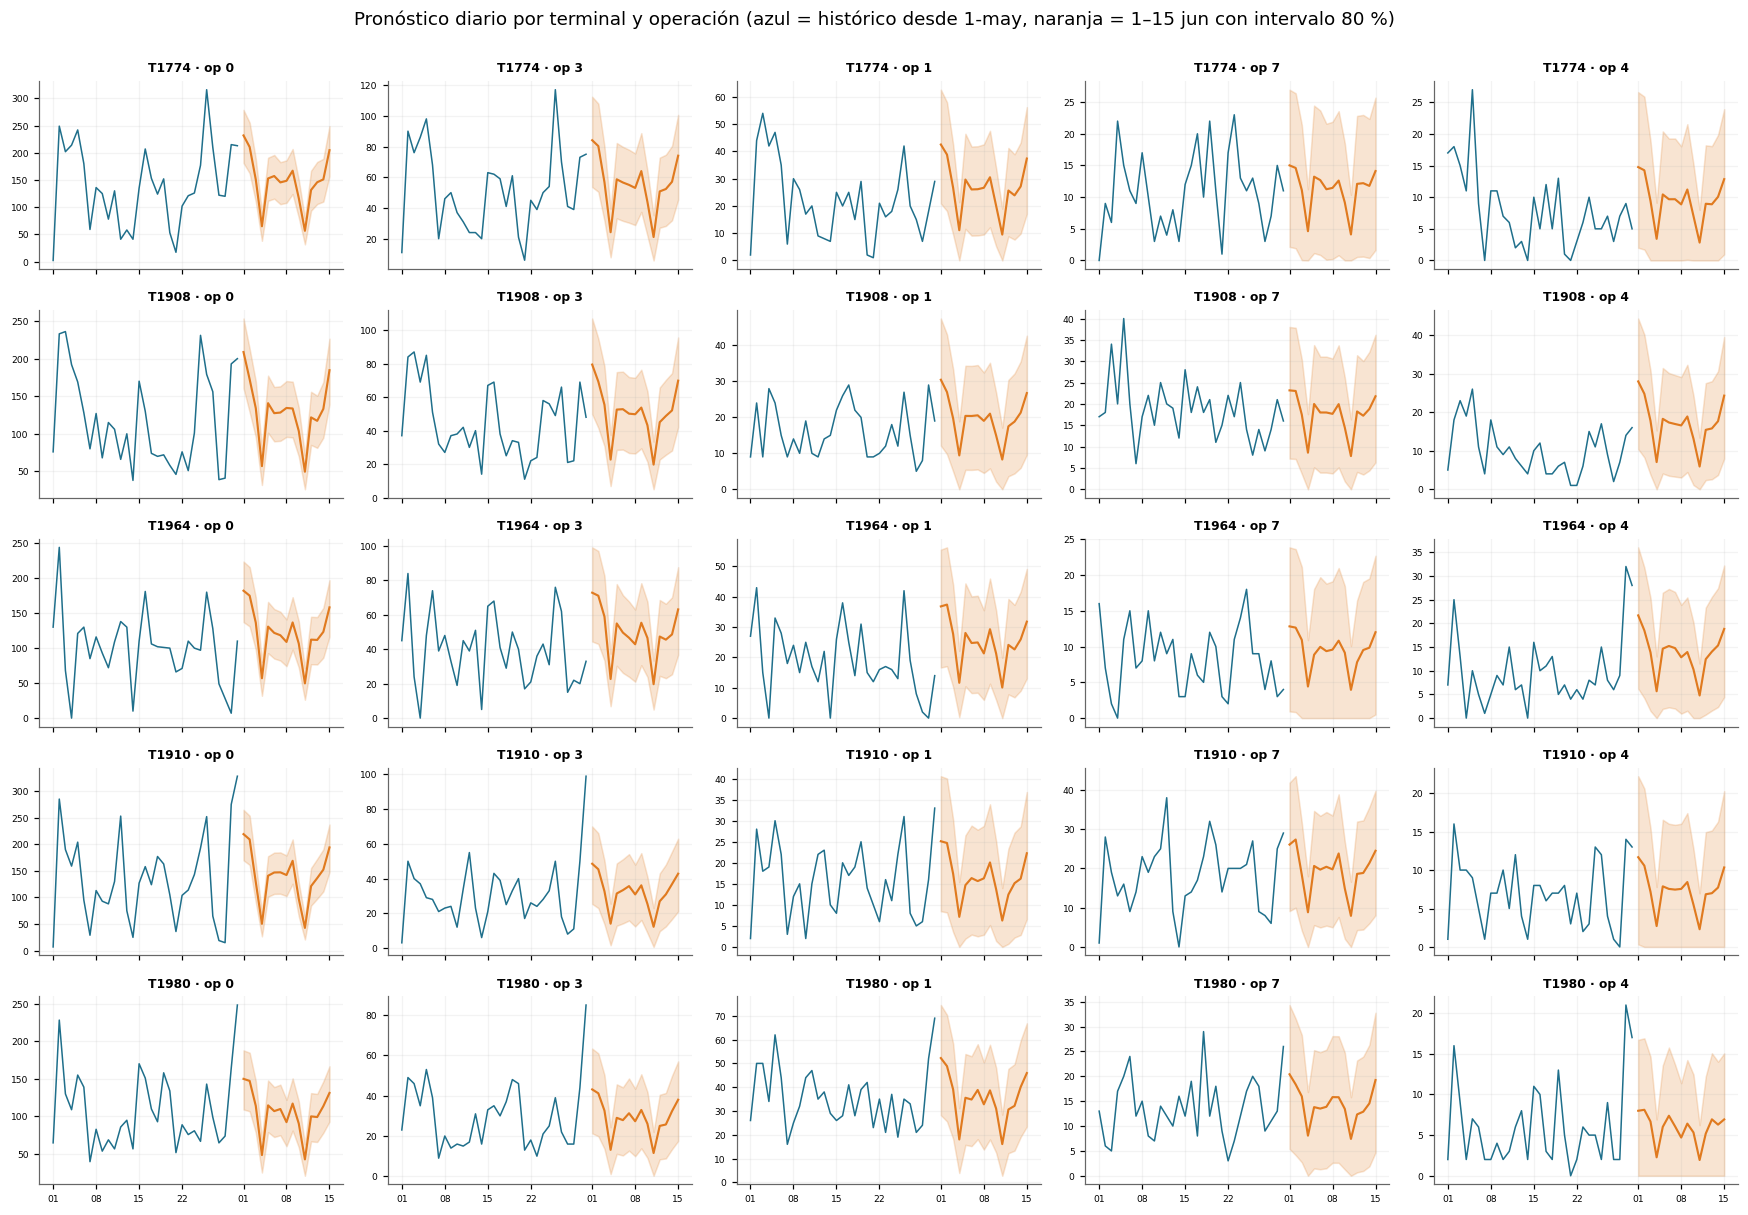

In [24]:
# Gráfica 1: total por día de las 25 series (histórico + pronóstico)
histd = P[P.sid.isin(SEL)].groupby('d').y.sum()
fd = fut.groupby('d').agg(pred=('pred', 'sum'), lo=('lo', 'sum'), hi=('hi', 'sum'))
# El intervalo del total no es la suma de intervalos (se asume independencia parcial): se aproxima con la suma de varianzas
var = (fut.assign(v=(fut.hi - fut.lo) / (zq[1] - zq[0])) .groupby('d').v.apply(lambda x: np.sqrt((x ** 2).sum())) * (zq[1] - zq[0]) / 2)
fd['lo'] = fd.pred - var * 1.0; fd['hi'] = fd.pred + var * 1.0
fig, ax = plt.subplots(figsize=(12, 4))
h = histd[histd.index >= '2017-04-01']
ax.plot(h.index, h.values, color=ACC, lw=1.6, label='Histórico (25 series)')
ax.plot(fd.index, fd.pred, color='#E07A1F', lw=2, marker='o', ms=3, label='Pronóstico')
ax.fill_between(fd.index, fd.lo, fd.hi, color='#E07A1F', alpha=.2, label='Intervalo aprox. 80 %')
for p in PAY[(PAY >= '2017-04-01') & (PAY <= '2017-06-15')]: ax.axvline(p, color=GRY, ls='--', lw=.8)
ax.set_title('Demanda diaria agregada de las 25 series seleccionadas: histórico y pronóstico 1–15 jun'); ax.legend(); ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
save('fig_forecast_total'); plt.show()

# Gráfica 2: pequeñas múltiplos por terminal y operación
fig, axs = plt.subplots(len(TERM), len(OPS), figsize=(16, 11), sharex=True)
for i, t in enumerate(TERM):
    for j, o in enumerate(OPS):
        a = axs[i, j]; sid = f'{t}_{o}'
        hh_ = P[(P.sid == sid) & (P.d >= '2017-05-01')]; ff = fut[fut.sid == sid]
        a.plot(hh_.d, hh_.y, color=ACC, lw=1); a.plot(ff.d, ff.pred, color='#E07A1F', lw=1.4); a.fill_between(ff.d, ff.lo, ff.hi, color='#E07A1F', alpha=.2)
        a.set_title(f'T{t} · op {o}', fontsize=8); a.tick_params(labelsize=6); a.xaxis.set_major_formatter(mdates.DateFormatter('%d')); a.grid(alpha=.15)
plt.suptitle('Pronóstico diario por terminal y operación (azul = histórico desde 1-may, naranja = 1–15 jun con intervalo 80 %)', y=1.0)
plt.tight_layout(); save('fig_grid'); plt.show()

**Lectura del pronóstico**
- Se esperan **picos el 1–2 de junio** (efecto fin de mes) y el **15 de junio** (pago de quincena), con valles los domingos 4 y 11 de junio.
- Se muestra la banda del 80 %: conviene dimensionar capacidad con el **límite superior** en los días pico y con la media en días normales.

In [25]:
# Calendario del pico esperado para planificación: días con mayor volumen pronosticado
tab = fut.groupby('d').pred.sum().round(0).astype(int).rename('pronostico_total_25_series').to_frame()
tab['dia'] = tab.index.strftime('%a'); tab['indice_vs_promedio'] = (tab.iloc[:, 0] / tab.iloc[:, 0].mean()).round(2)
print(tab.to_string())

            pronostico_total_25_series  dia  indice_vs_promedio
d                                                              
2017-06-01                        1689  Thu                1.52
2017-06-02                        1571  Fri                1.41
2017-06-03                        1160  Sat                1.04
2017-06-04                         488  Sun                0.44
2017-06-05                        1169  Mon                1.05
2017-06-06                        1134  Tue                1.02
2017-06-07                        1122  Wed                1.01
2017-06-08                        1071  Thu                0.96
2017-06-09                        1247  Fri                1.12
2017-06-10                         903  Sat                0.81
2017-06-11                         425  Sun                0.38
2017-06-12                        1010  Mon                0.91
2017-06-13                        1050  Tue                0.94
2017-06-14                        1165  

## 6. Conclusiones, limitaciones y uso para la entidad
**Hallazgos clave**
1. La demanda tiene **tres drivers estables**: día de la semana (domingo ≈ 28 % de un miércoles), **calendario de pago** (día de pago y siguiente ≈ +41–49 %) y **festivos** (caídas fuertes). El perfil horario es estable (9–18 h).
2. Hay **alta concentración**: 5 operaciones = 92 % del volumen, y la op 0 sola = 55 %; unas pocas terminales concentran gran parte del volumen, con una brecha ≈7x entre las más y menos cargadas.
3. El ensamble final reduce el error diario ≈38 % frente al naive y ≈17 % frente a la media semanal, con sesgo +5 %; predice el **total de 15 días por serie con ≈13 % de error** (empate práctico con la media semanal, que ya capta el nivel) y el volumen diario de toda la entidad (220 series) con ≈20 %. El error diario por serie (≈35 %) es alto: festivos y fallas de terminal no se anticipan.

**Cómo aprovecharlo**
- **Capacidad y personal:** planificar los picos de quincena con 15 días de antelación y usar el límite superior del intervalo; reducir cobertura/mantenimiento programado en domingos y festivos.
- **Mantenimiento y reposición:** programar ventanas de mantenimiento y reposición de insumos/efectivo en los valles del pronóstico.
- **Utilización de terminales:** revisar terminales de bajo volumen (reubicar, cambiar configuración de operaciones) y redistribuir carga de las de mayor volumen en hora pico.
- **Monitoreo:** alerta si el real se aleja del intervalo del 80 % → indica posible falla o cambio de comportamiento (en backtest, 6 terminal-días hábiles normales —2 %— cayeron por debajo de la mitad de lo esperado, entre ellos una caída a 0 transacciones).

**Limitaciones y próximos pasos:** 4 meses de historia (sin estacionalidad anual), demanda observada ≠ demanda real (censura), sin diccionario de operaciones, selección sesgada hacia terminales de alto volumen. Próximos pasos: ampliar historia, añadir estado de terminal y campañas, reentrenar mensualmente y monitorear WAPE por terminal.